In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [7]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi
import matplotlib

In [8]:
prefix = '/mnt/staging/'
figure_config_root = str(PREPARES / "config") + "/"
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# # for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#cd80a1'
palatte_dict['tail'] = 'palegreen'
palatte_dict['LT'] = '#b3b3b3'
palatte_dict['RT']  = '#e4c494' ##b69d76 back up
palatte_dict['RT']  = '#b69d76' # back up

In [9]:
atlas = scipy.io.loadmat('atlas.mat')['atlas']
areanames = scipy.io.loadmat('atlas.mat')['areanames']

In [10]:
atlas[atlas==0]=np.nan
atlas[atlas==-301]=np.nan # remove OLB
atlas[atlas==301]=np.nan # remove OLB

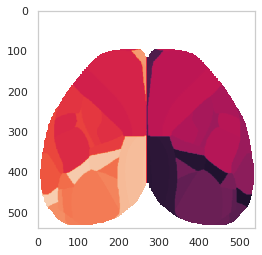

In [6]:
plt.imshow(atlas)

In [8]:
print(palatte_dict.keys())

dict_keys(['RFP', 'LFP', 'RM', 'LM', 'RW', 'LW', 'RHP', 'LHP', 'RN', 'LN', 'RV', 'LV', 'ALM', 'RSP', 'RM_M2', 'RM_M1', 'RFP_M2', 'RFP_M1', 'RM_S1', 'RFP_S1'])


In [14]:
dict_color_matching = {
'SSp_tr':palatte_dict['RT'],'SSp_n':palatte_dict['RN'],
'SSp_bfd':palatte_dict['RW'],'SSp_ll':palatte_dict['RHP'],'SSp_m':palatte_dict['RM'],
'VIS':palatte_dict['RV'],'RSP':palatte_dict['RSP'],'SSp_ul':palatte_dict['RFP'],
    # 'MOp':'#ADD8E6','MOs':'#74ca6a'   
    'MOp':'lightgray','MOs':'darkgray'  ,'SSs':'darkslategray'
}

In [12]:
areas = np.unique(atlas).astype('int')
areas = areas[areas>-1000]

In [13]:
def parse_areanames(areanames_):
    areainds=[]; areanames=[];
    for i,area in enumerate(areanames_[0][0]):
        areainds.append(area[0][0])
        areanames.append(areanames_[0][0].dtype.descr[i][0])
    sortvec=np.argsort(np.abs(areainds))
    areanames=[areanames[i] for i in sortvec]
    areainds=[areainds[i] for i in sortvec]
    return areainds,areanames

In [14]:
# Get area names for all components
areainds,areanames_all = parse_areanames(areanames)
areanames_area=[]
areainds_area=[]
dict_ind_area = {}
for i,area in enumerate(areas):
    areanames_area.append(areanames_all[areainds.index(area)])
    areainds_area.append(areainds.index(area))
    dict_ind_area[areanames_all[areainds.index(area)]] = area

In [15]:
color_dict = {}

# Fixing random seed for consistent colors
np.random.seed(42)

for name in areanames_area:
    color_assigned = False
    for key in dict_color_matching:
        if key in name:
            color_dict[name] = dict_color_matching[key]
            color_assigned = True
            break
    if not color_assigned:
        # Generate a random color in hexadecimal format
        # random_color = "#{:06x}".format(random.randint(0, 0xFFFFFF))
        color_dict[name] = 'black'#random_color



In [16]:
# (137,130) #bregma location
pixels_per_mm = 50.79
x_axis = np.divide(np.linspace(-270,540-270-1,540),pixels_per_mm)
y_axis = np.divide(np.linspace(540-270-1,-270,540),pixels_per_mm)
extent_allen = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]


(539.5, -0.5)
(-0.5, 539.5)


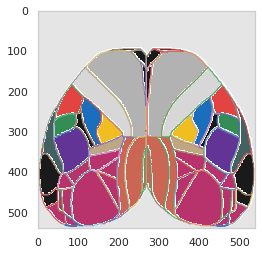

In [17]:
from skimage import measure
# plt.figure(dpi=300)
for areaname in areanames_area:
    c_black= matplotlib.colors.colorConverter.to_rgba(color_dict[areaname],alpha = 1)
    c_black1= matplotlib.colors.colorConverter.to_rgba(color_dict[areaname],alpha = 0.95)
    c_white= matplotlib.colors.colorConverter.to_rgba(color_dict[areaname],alpha = 0.9)
    cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)

    ind_area = dict_ind_area[areaname]
    
    map_here = atlas==ind_area
    map_here = map_here.astype('float')
    map_here[map_here==0]=np.nan
    
    filled_bw = scipy.ndimage.morphology.binary_fill_holes(map_here>0.2)
    contours = measure.find_contours(filled_bw, 0.8)

    plt.imshow(map_here,cmap=cmap_rb)
    for contour in contours:
        plt.plot(contour[:,1],contour[:,0],linewidth=1)
        
        
    # plt.ylim([-5.31,4])

c_black= matplotlib.colors.colorConverter.to_rgba('#e3e3e3',alpha = 1)
c_black1= matplotlib.colors.colorConverter.to_rgba('#e3e3e3',alpha = 0.95)
c_white= matplotlib.colors.colorConverter.to_rgba('#e3e3e3',alpha = 0.9)
cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)


map_here = np.nan_to_num(atlas.copy(),0)==0
map_here = map_here.astype('float')
map_here[map_here==0]=np.nan

plt.imshow(map_here,cmap=cmap_rb)
# plt.ylim([-5.31,4])

    
print(plt.gca().get_ylim())
print(plt.gca().get_xlim())

    # plt.scatter(270,270)
    # plt.scatter(270,110)
plt.savefig('fig1-Allen-just-contours.svg',format='svg',dpi=300)

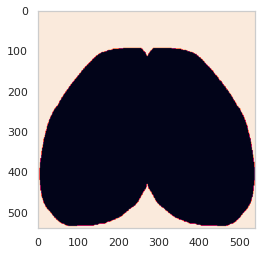

In [18]:
map_here = np.nan_to_num(atlas.copy(),0)==0
plt.imshow(map_here)

# make allen atlas figure

Text(0, 0.5, 'P-A (mm)')

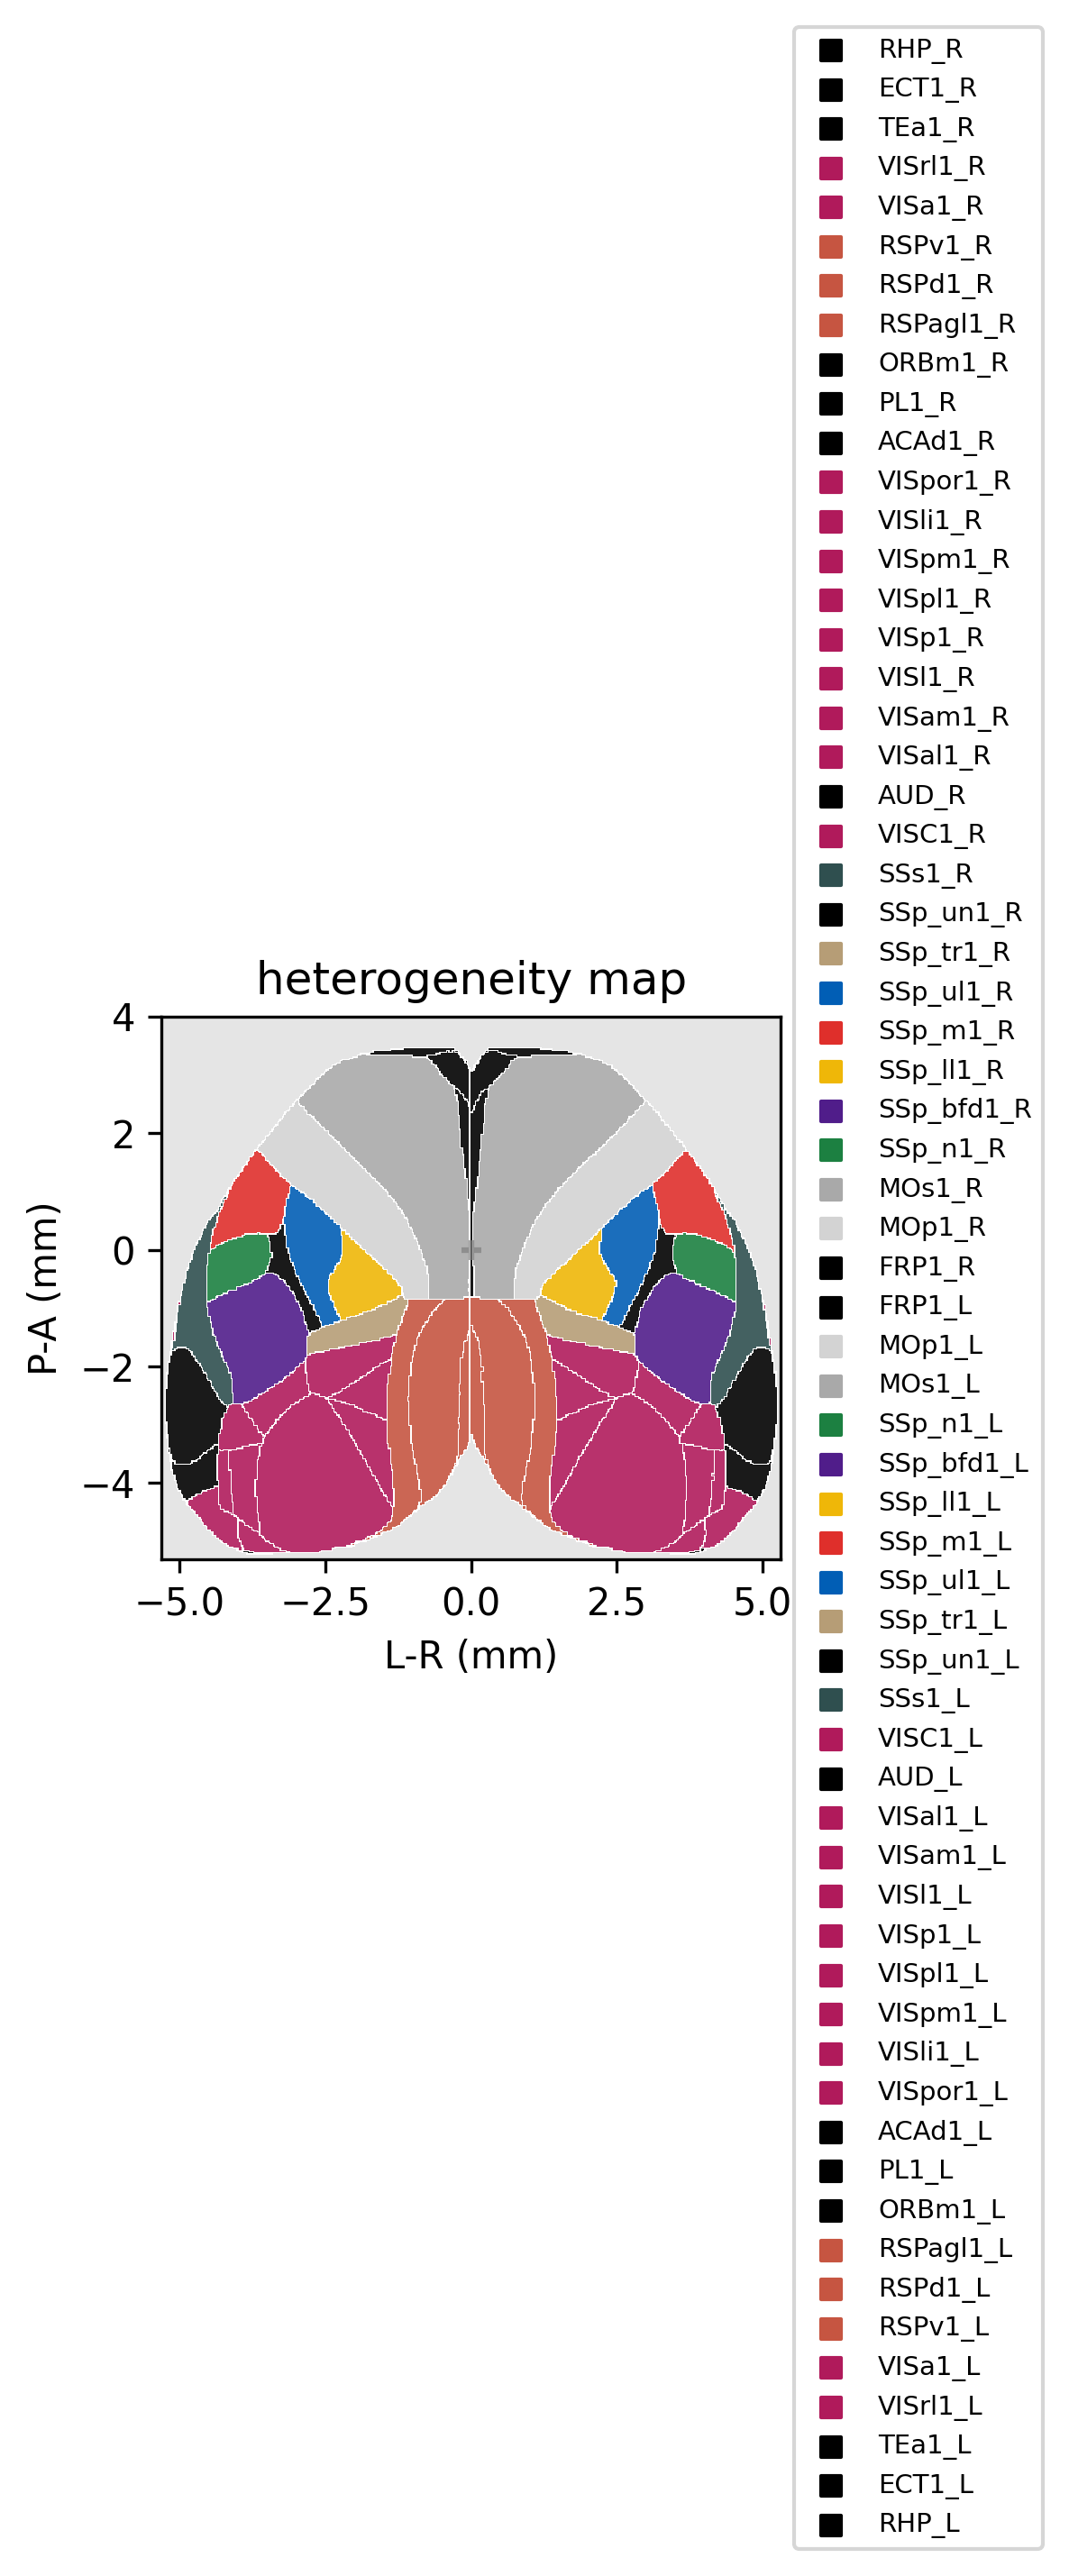

In [19]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)



y_offset = 20;x_offset=20;
x_width=10;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+10,x_start:x_stop])

for areaname in areanames_area:
    c_black= matplotlib.colors.colorConverter.to_rgba(color_dict[areaname],alpha = 1)
    c_black1= matplotlib.colors.colorConverter.to_rgba(color_dict[areaname],alpha = 0.95)
    c_white= matplotlib.colors.colorConverter.to_rgba(color_dict[areaname],alpha = 0.9)
    cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)

    ind_area = dict_ind_area[areaname]
    
    map_here = atlas==ind_area
    map_here = map_here.astype('float')
    map_here[map_here==0]=np.nan

    ax0.imshow(map_here,cmap=cmap_rb,extent=extent_allen)
    ax0.set_ylim([-5.31,4])
    ax0.set_xlim([-5.31,5.31])
    
    # for legend
    ax0.scatter(6,6,marker='s',s=30,label=areaname,color=color_dict[areaname])

    
c_black= matplotlib.colors.colorConverter.to_rgba('#e3e3e3',alpha = 1)
c_black1= matplotlib.colors.colorConverter.to_rgba('#e3e3e3',alpha = 0.95)
c_white= matplotlib.colors.colorConverter.to_rgba('#e3e3e3',alpha = 0.9)
cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)
map_here = np.nan_to_num(atlas.copy(),0)==0
map_here = map_here.astype('float')
map_here[map_here==0]=np.nan
plt.imshow(map_here,cmap=cmap_rb,extent=extent_allen)
plt.ylim([-5.31,4])



ax0.scatter(0,0,s=30,marker='+',color='gray',alpha=0.7) #bregma location
ax0.legend(loc='center left',fontsize=7, bbox_to_anchor=(1, 0.5))
ax0.set_title('heterogeneity map')
ax0.set_xlabel('L-R (mm)')
ax0.set_ylabel('P-A (mm)')
    
plt.savefig('fig1-Allen.svg',format='svg',dpi=300)

In [28]:
print(ax0.get_xlim(),ax0.get_ylim())

(-5.31, 5.31) (-5.31, 4.0)


# compare cranial window

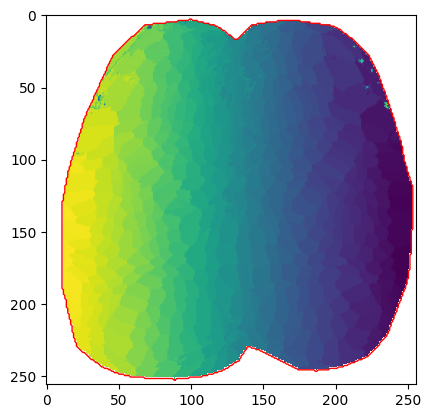

In [25]:
step_0_root = str(STEPS / "step_0") + "/"
mouse='cm125'
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
    
# Find contours
contours = measure.find_contours(mask>0, level=0.5)
    
plt.imshow(IDX_sorted)
for contour in contours:
    plt.plot(contour[:, 1], contour[:, 0], linewidth=1, color='red')

In [37]:
# (135,136) #bregma location
pixels_per_mm = 31
x_axis = np.divide(np.linspace(-135,256-135-1,256),pixels_per_mm)
y_axis = np.divide(np.linspace(256-136-1,-136,256),pixels_per_mm)
extent = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]


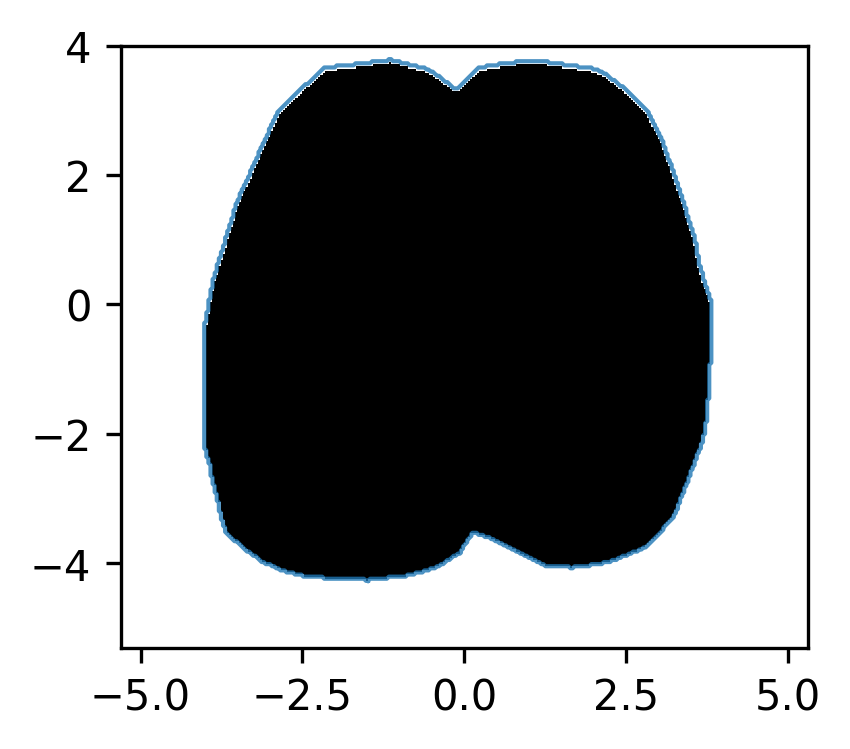

In [38]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;
x_width=10;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+10,x_start:x_stop])

ax0.imshow(mask,cmap='gray',vmin=0,vmax=4500,extent=extent)
ax0.set_xlim((-5.31, 5.31))
ax0.set_ylim((-5.31, 4.0))

for contour in contours:
    ax0.plot((contour[:,1]-135)/pixels_per_mm,(256-contour[:,0]-136)/pixels_per_mm,linewidth=1,alpha=0.8,)

plt.savefig('fig1-cranial-window-contour.svg',format='svg',dpi=300)